# Predicting Income Level (>50K) using Random Forest
**Name:** Akshat Shankar Bidwai  
**Dataset:** Adult Census Income (`adult.data`, UCI / Kaggle)  
**Goal:** Predict whether a person earns more than 50K a year (`1`) or not (`0`).

**Workflow:** Load data → Clean data → EDA → Plots → Encode & split → Random Forest → Evaluate → Tune

## 1. Import Libraries

In [ ]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
os.makedirs('figures', exist_ok=True)   # folder to save high-resolution plots

def save_fig(name):
    """Save the current plot as a high-resolution PNG, then show it."""
    plt.tight_layout()
    plt.savefig(f'figures/{name}.png', dpi=200, bbox_inches='tight')
    plt.show()

## 2. Load the Data
`adult.data` has **no header row**, so we give the column names ourselves.
`skipinitialspace=True` removes the extra space after every comma in the file.

In [ ]:
columns = ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status',
           'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss',
           'hours_per_week', 'native_country', 'income']

# If you use Google Colab, upload adult.data first (files.upload()) and keep the same name.
df = pd.read_csv('adult.data', names=columns, skipinitialspace=True)

print('Shape:', df.shape)
df.head()

Shape: (32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 3. Data Cleaning

### 3.1 First look: data types, missing values and duplicates

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education_num   32561 non-null  int64
 5   marital_status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital_gain    32561 non-null  int64
 11  capital_loss    32561 non-null  int64
 12  hours_per_week  32561 non-null  int64
 13  native_country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [ ]:
# Missing values: the file uses '?' instead of NaN, so isnull() shows nothing
print('Real NaN values :', df.isnull().sum().sum())
print('\nColumns that contain "?":')
for col in df.select_dtypes(exclude='number'):
    n = (df[col] == '?').sum()
    if n > 0:
        print(f'  {col}: {n}')
print('\nDuplicate rows:', df.duplicated().sum())

Real NaN values : 0

Columns that contain "?":
  workclass: 1836
  occupation: 1843
  native_country: 583

Duplicate rows: 24


### 3.2 Fix the `income` column
The target column is text (`object`). We will:
1. **Fix spelling / formatting errors** – remove stray spaces and trailing full stops, and make everything lower-case, so variants like `' <=50K'`, `'>50K.'` or `'>50k'` all become one clean label.
2. **Convert to 0 and 1** – `<=50K` → `0`, `>50K` → `1`.
3. **Convert from `object` to `int`.**

In [ ]:
print('Before cleaning:')
print(df['income'].value_counts())

# Step 1: fix spelling / formatting errors
df['income'] = (df['income']
                .str.strip()            # remove leading/trailing spaces
                .str.replace('.', '', regex=False)   # remove trailing full stop
                .str.lower())           # '>50K' and '>50k' become the same

# Step 2: convert text to 0 and 1
df['income'] = df['income'].map({'<=50k': 0, '>50k': 1})

# Safety check: any label we could not map would become NaN
print('\nUnmapped income values:', df['income'].isnull().sum())

# Step 3: object -> int
df['income'] = df['income'].astype(int)

print('\nAfter cleaning:')
print(df['income'].value_counts())
print('Data type of income:', df['income'].dtype)

Before cleaning:
income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Unmapped income values: 0

After cleaning:
income
0    24720
1     7841
Name: count, dtype: int64
Data type of income: int64


### 3.3 Handle missing values (`?`) and duplicates
`workclass`, `occupation` and `native_country` contain `?`. These are categorical columns, so we replace `?` with `NaN`
and fill them with the **mode** (most common value). Duplicate rows are removed.

In [ ]:
# Replace '?' with NaN, then fill with the most common value (mode) of each column
df = df.replace('?', np.nan)
for col in ['workclass', 'occupation', 'native_country']:
    df[col] = df[col].fillna(df[col].mode()[0])

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print('Missing values left:', df.isnull().sum().sum())
print('Duplicates left    :', df.duplicated().sum())
print('Shape now          :', df.shape)

Missing values left: 0


Duplicates left    : 0
Shape now          : (32537, 15)


### 3.4 Drop columns we do not need
- `education` is the same information as `education_num` (just text vs. number), so we keep only the number.
- `fnlwgt` is a census sampling weight and does not describe the person.

In [ ]:
df = df.drop(columns=['education', 'fnlwgt'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32537 entries, 0 to 32536
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32537 non-null  int64
 1   workclass       32537 non-null  str  
 2   education_num   32537 non-null  int64
 3   marital_status  32537 non-null  str  
 4   occupation      32537 non-null  str  
 5   relationship    32537 non-null  str  
 6   race            32537 non-null  str  
 7   sex             32537 non-null  str  
 8   capital_gain    32537 non-null  int64
 9   capital_loss    32537 non-null  int64
 10  hours_per_week  32537 non-null  int64
 11  native_country  32537 non-null  str  
 12  income          32537 non-null  int64
dtypes: int64(6), str(7)
memory usage: 3.2 MB


## 4. Exploratory Data Analysis (EDA)

In [ ]:
df.describe()

,age,education_num,capital_gain,capital_loss,hours_per_week,income
count,32537.000000,32537.000000,32537.000000,32537.000000,32537.000000,32537.000000
mean,38.585549,10.081815,1078.443741,87.368227,40.440329,0.240926
std,13.637984,2.571633,7387.957424,403.101833,12.346889,0.427652
min,17.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,28.000000,9.000000,0.000000,0.000000,40.000000,0.000000
50%,37.000000,10.000000,0.000000,0.000000,40.000000,0.000000
75%,48.000000,12.000000,0.000000,0.000000,45.000000,0.000000
max,90.000000,16.000000,99999.000000,4356.000000,99.000000,1.000000


In [ ]:
# Class imbalance check
print(df['income'].value_counts())
print()
print((df['income'].value_counts(normalize=True) * 100).round(2))

income
0    24698
1     7839
Name: count, dtype: int64

income
0    75.91
1    24.09
Name: proportion, dtype: float64


**Observation:** only about 1 in 4 people earn more than 50K, so the data is **imbalanced**.
Accuracy alone can be misleading, so we will focus on Precision, Recall and F1-score for class `1`.

## 5. Plots

### 5.1 Univariate analysis

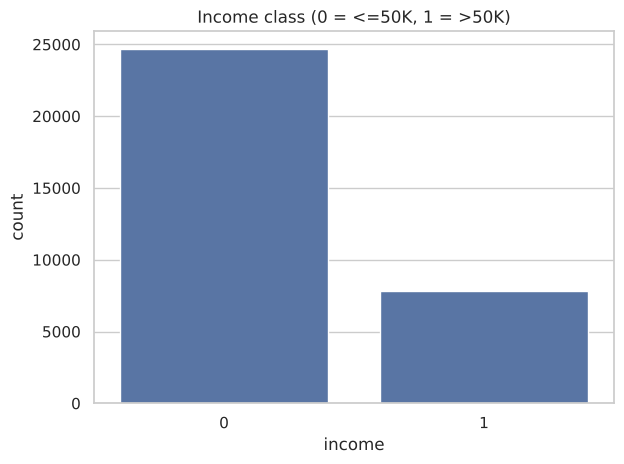

In [ ]:
# Target variable
sns.countplot(x='income', data=df)
plt.title('Income class (0 = <=50K, 1 = >50K)')
save_fig('01_income_count')

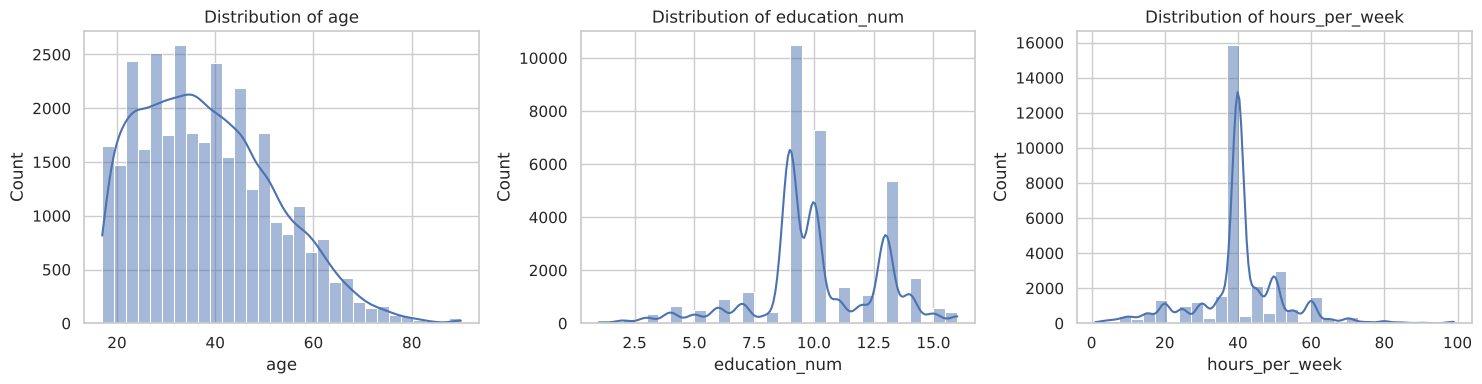

In [ ]:
# Numeric columns: distribution
num_cols = ['age', 'education_num', 'hours_per_week']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')
save_fig('02_numeric_distributions')

### 5.2 Bivariate analysis (feature vs income)

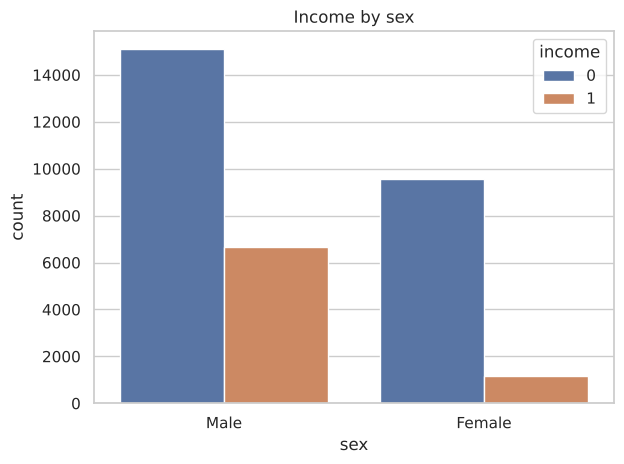

In [ ]:
sns.countplot(x='sex', hue='income', data=df)
plt.title('Income by sex')
save_fig('03_income_by_sex')

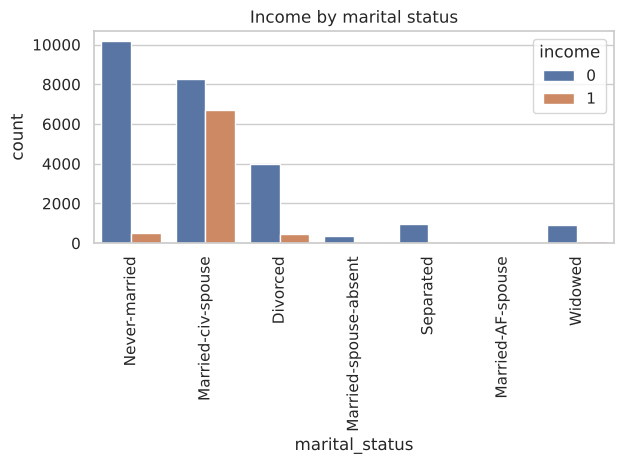

In [ ]:
sns.countplot(x='marital_status', hue='income', data=df)
plt.xticks(rotation=90)
plt.title('Income by marital status')
save_fig('04_income_by_marital_status')

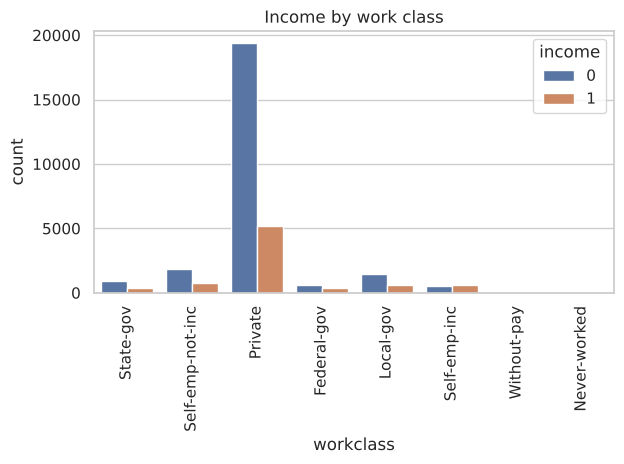

In [ ]:
sns.countplot(x='workclass', hue='income', data=df)
plt.xticks(rotation=90)
plt.title('Income by work class')
save_fig('05_income_by_workclass')

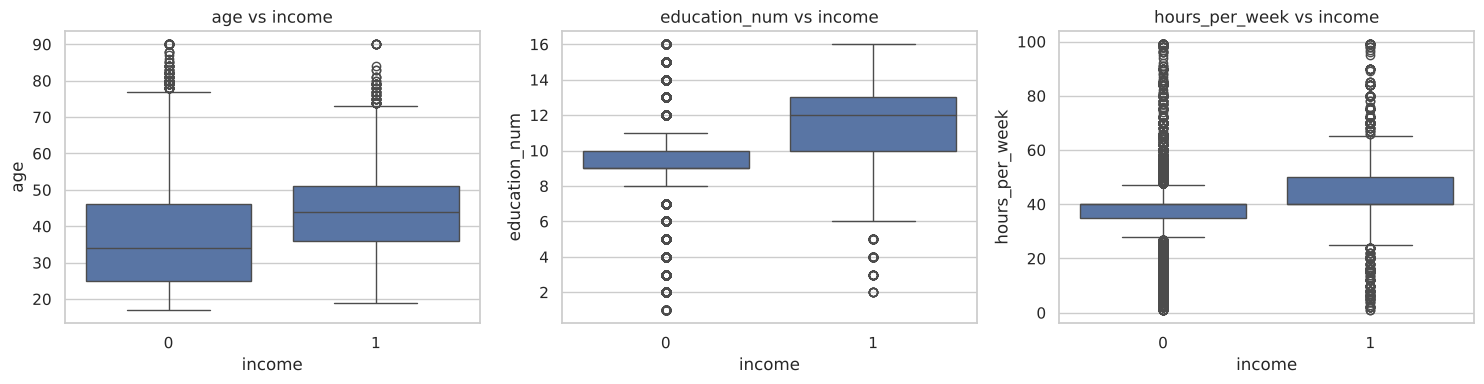

In [ ]:
# Numeric features vs income
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x='income', y=col, data=df, ax=ax)
    ax.set_title(f'{col} vs income')
save_fig('06_numeric_vs_income')

### 5.3 Outlier check

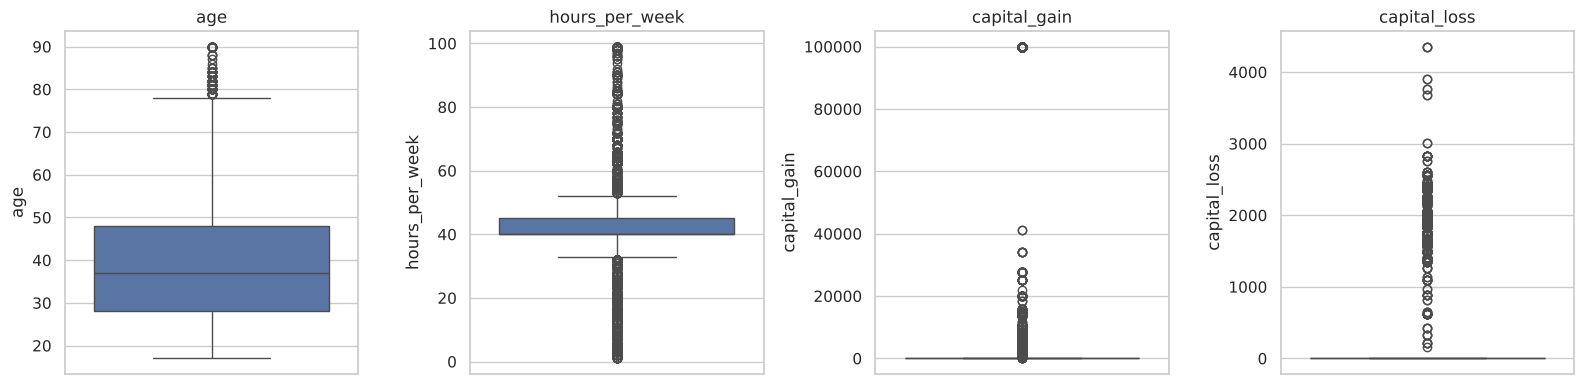

In [ ]:
cols = ['age', 'hours_per_week', 'capital_gain', 'capital_loss']
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
save_fig('07_outliers')

Outliers exist (e.g. very high `capital_gain`), but these are **real** values, not errors.
Random Forest splits data using thresholds, so it is not affected much by outliers. We keep them.

## 6. Encode, Correlation Heatmap and Train/Test Split
Machine learning models need numbers, so the remaining text (`object`) columns are converted with **Label Encoding**
(same as done in class). We use a copy so `df` stays readable.

In [ ]:
from sklearn.preprocessing import LabelEncoder

df_enc = df.copy()
le = LabelEncoder()
for col in df_enc.select_dtypes(exclude='number'):
    df_enc[col] = le.fit_transform(df_enc[col])

df_enc.info()

<class 'pandas.DataFrame'>
RangeIndex: 32537 entries, 0 to 32536
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32537 non-null  int64
 1   workclass       32537 non-null  int64
 2   education_num   32537 non-null  int64
 3   marital_status  32537 non-null  int64
 4   occupation      32537 non-null  int64
 5   relationship    32537 non-null  int64
 6   race            32537 non-null  int64
 7   sex             32537 non-null  int64
 8   capital_gain    32537 non-null  int64
 9   capital_loss    32537 non-null  int64
 10  hours_per_week  32537 non-null  int64
 11  native_country  32537 non-null  int64
 12  income          32537 non-null  int64
dtypes: int64(13)
memory usage: 3.2 MB


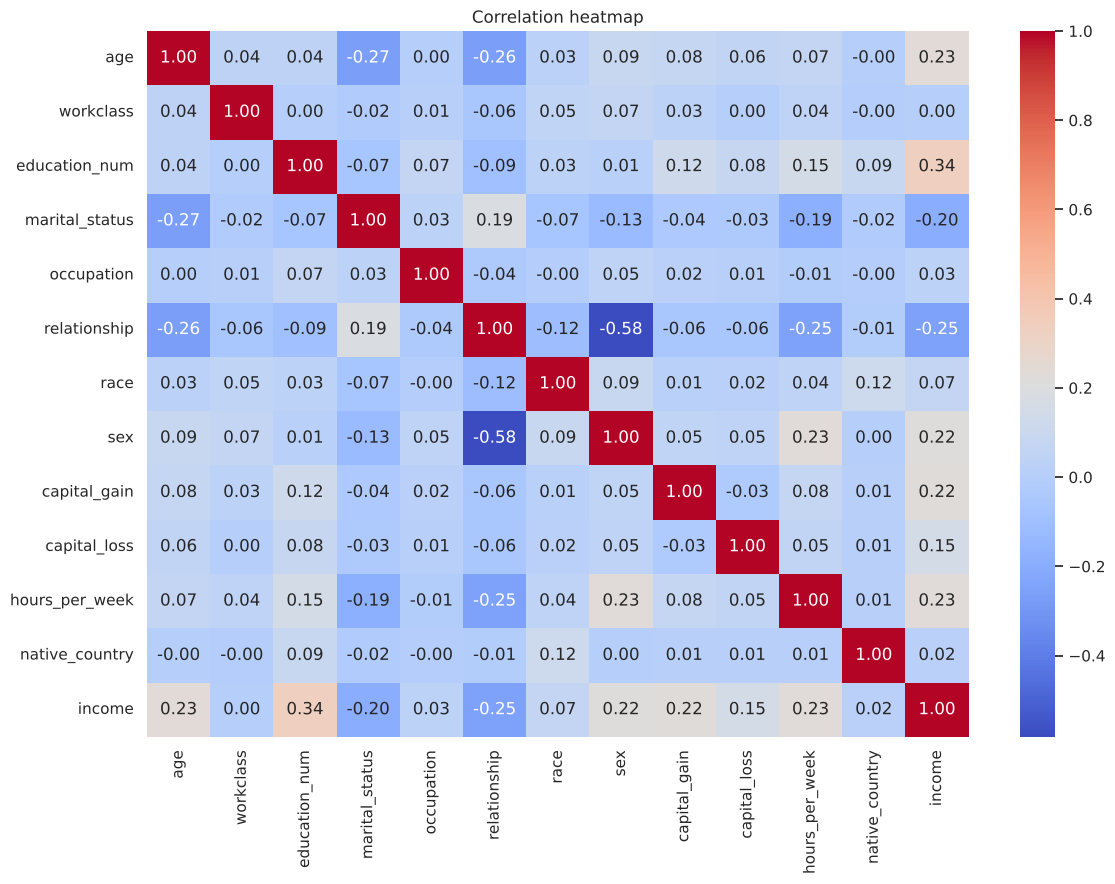

In [ ]:
# Correlation of every feature with income
plt.figure(figsize=(12, 9))
sns.heatmap(df_enc.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation heatmap')
save_fig('08_correlation_heatmap')

In [ ]:
# Split: 80% train, 20% test. stratify keeps the same income ratio in both parts.
from sklearn.model_selection import train_test_split

X = df_enc.drop('income', axis=1)
y = df_enc['income']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (26029, 12)  Test: (6508, 12)


### 6.1 Handle class imbalance with SMOTE
SMOTE creates synthetic samples of the minority class (`>50K`). It is applied **only on the training data**
so the test data stays real.

*Feature scaling is skipped on purpose: Random Forest uses split thresholds, not distances, so scale does not matter.*

In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print('Before SMOTE:\n', y_train.value_counts())
print('After SMOTE:\n', y_train_smote.value_counts())

Before SMOTE:
 income
0    19758
1     6271
Name: count, dtype: int64
After SMOTE:
 income
0    19758
1    19758
Name: count, dtype: int64


## 7. Random Forest Model
A Random Forest builds many decision trees and takes a majority vote.
First we use a simple model with default settings as a **baseline**.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_smote, y_train_smote)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print('Train accuracy:', round(accuracy_score(y_train, y_train_pred), 4))
print('Test accuracy :', round(accuracy_score(y_test, y_test_pred), 4))
print()
print(classification_report(y_test, y_test_pred, target_names=['<=50K', '>50K']))

Train accuracy: 0.9685
Test accuracy : 0.8354

              precision    recall  f1-score   support

       <=50K       0.91      0.87      0.89      4940
        >50K       0.64      0.73      0.68      1568

    accuracy                           0.84      6508
   macro avg       0.77      0.80      0.78      6508
weighted avg       0.84      0.84      0.84      6508



The train accuracy is much higher than the test accuracy, which means the default trees **overfit** (they are too deep and memorise the training data).
We fix this by tuning `n_estimators`, `max_depth` and `min_samples_leaf`.

## 8. Hyperparameter Tuning (GridSearchCV)
- `n_estimators` – number of trees. More trees = more stable, but slower.
- `max_depth` – how deep each tree can grow. Smaller depth reduces overfitting.
- `min_samples_leaf` – minimum samples in a leaf. A larger value gives smoother, simpler trees.

We score with **F1** because the data is imbalanced.

In [ ]:
from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import Pipeline

# SMOTE is placed INSIDE the pipeline so that, during cross-validation, synthetic samples are
# created only from the training folds. (Tuning on already-SMOTEd data would leak copies of
# the same person into the validation fold and give over-optimistic scores.)
pipe = Pipeline([('smote', SMOTE(random_state=42)),
                 ('rf', RandomForestClassifier(random_state=42))])

param_grid = {
    'rf__n_estimators': [100, 200],
    'rf__max_depth': [None, 10, 20],
    'rf__min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(pipe, param_grid, cv=3, scoring='f1', n_jobs=-1)
grid_search.fit(X_train, y_train)      # original (not SMOTEd) training data

print('Best parameters:', grid_search.best_params_)
print('Best CV F1-score:', round(grid_search.best_score_, 4))

Best parameters: {'rf__max_depth': None, 'rf__min_samples_leaf': 4, 'rf__n_estimators': 200}
Best CV F1-score: 0.6954


In [ ]:
best_model = grid_search.best_estimator_
y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

print('Train accuracy:', round(accuracy_score(y_train, y_train_pred), 4))
print('Test accuracy :', round(accuracy_score(y_test, y_test_pred), 4))

Train accuracy: 0.8746
Test accuracy : 0.8405


## 9. Model Evaluation

### 9.1 Classification report (Precision, Recall, F1-score)

In [ ]:
print(classification_report(y_test, y_test_pred, target_names=['<=50K', '>50K']))

              precision    recall  f1-score   support

       <=50K       0.94      0.85      0.89      4940
        >50K       0.63      0.82      0.71      1568

    accuracy                           0.84      6508
   macro avg       0.78      0.83      0.80      6508
weighted avg       0.86      0.84      0.85      6508



### 9.2 Confusion matrix

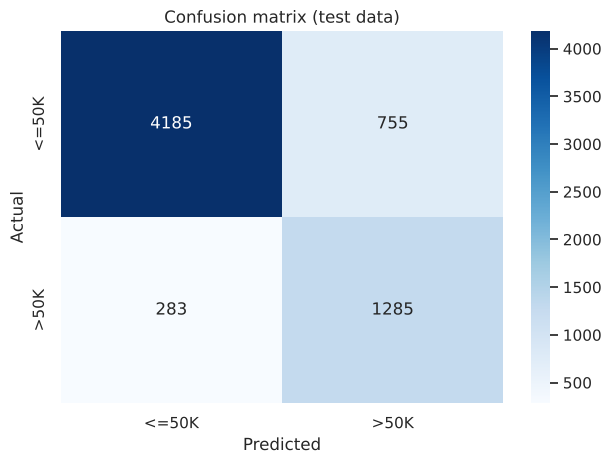

True Negatives: 4185 | False Positives: 755 | False Negatives: 283 | True Positives: 1285


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['<=50K', '>50K'], yticklabels=['<=50K', '>50K'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix (test data)')
save_fig('09_confusion_matrix')

tn, fp, fn, tp = cm.ravel()
print(f'True Negatives: {tn} | False Positives: {fp} | False Negatives: {fn} | True Positives: {tp}')

### 9.3 ROC curve and AUC

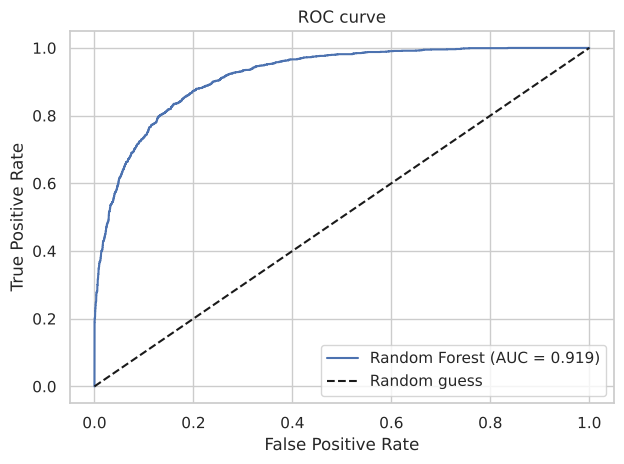

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

y_prob = best_model.predict_proba(X_test)[:, 1]     # probability of income >50K
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label=f'Random Forest (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve')
plt.legend()
save_fig('10_roc_curve')

### 9.4 Feature importance

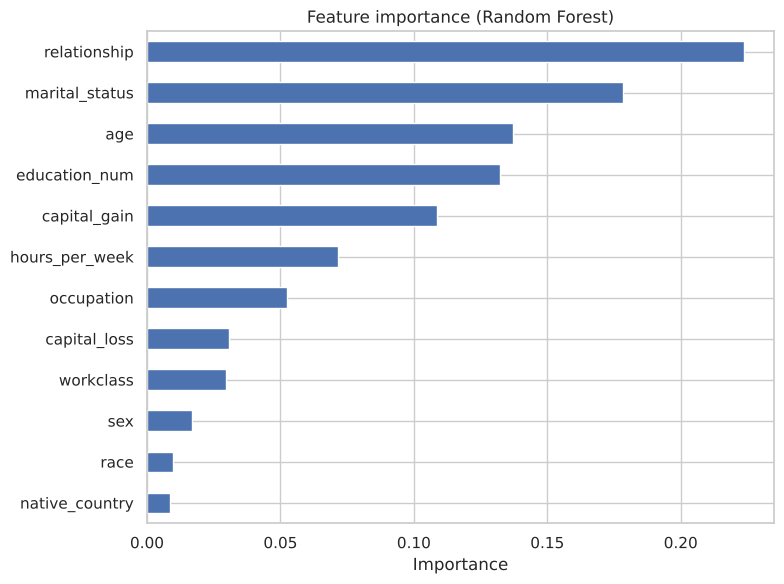

relationship      0.2238
marital_status    0.1784
age               0.1373
education_num     0.1322
capital_gain      0.1085
hours_per_week    0.0717
occupation        0.0526
capital_loss      0.0309
workclass         0.0295
sex               0.0168
race              0.0097
native_country    0.0086
dtype: float64


In [ ]:
importance = pd.Series(best_model.named_steps['rf'].feature_importances_, index=X.columns).sort_values()

importance.plot(kind='barh', figsize=(8, 6))
plt.xlabel('Importance')
plt.title('Feature importance (Random Forest)')
save_fig('11_feature_importance')

print(importance.sort_values(ascending=False).round(4))

## 10. Why did we get these results?
Numbers alone are not enough, so we test the reasons behind them.

**(a) Why is recall high but precision lower for the >50K class?** We train the same tuned model *with* and *without* SMOTE.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Same tuned settings, trained on the original (imbalanced) training data - no SMOTE
rf_no_smote = RandomForestClassifier(n_estimators=grid_search.best_params_['rf__n_estimators'],
                                     max_depth=grid_search.best_params_['rf__max_depth'],
                                     min_samples_leaf=grid_search.best_params_['rf__min_samples_leaf'],
                                     random_state=42).fit(X_train, y_train)
pred_no_smote = rf_no_smote.predict(X_test)

why = {}
for name, pred in [('Without SMOTE', pred_no_smote), ('With SMOTE', y_test_pred)]:
    why[name] = dict(precision=precision_score(y_test, pred), recall=recall_score(y_test, pred), f1=f1_score(y_test, pred))
pd.DataFrame(why).T.round(2)

,precision,recall,f1
Without SMOTE,0.79,0.64,0.71
With SMOTE,0.63,0.82,0.71


**Reason:** SMOTE makes the training data 50/50, so the model "believes" high earners are far more common than they really are (24%).
It therefore says `>50K` more often: it catches more real high earners (**recall goes up**) but also wrongly flags more people (**precision goes down**).
The F1-score stays about the same - SMOTE *moves* the balance between precision and recall, it does not make the model better overall.

**(b) Which high earners does the model miss (false negatives), and which people does it wrongly flag (false positives)?**

In [ ]:
# Compare average feature values of groups of people in the test set
test = X_test.copy()
test['actual'] = y_test
test['pred'] = y_test_pred
feats = ['age', 'education_num', 'hours_per_week', 'capital_gain']

groups = {
    'High earners CAUGHT (TP)':  test[(test.actual == 1) & (test.pred == 1)][feats].mean(),
    'High earners MISSED (FN)':  test[(test.actual == 1) & (test.pred == 0)][feats].mean(),
    'Low earners WRONGLY flagged (FP)': test[(test.actual == 0) & (test.pred == 1)][feats].mean(),
    'Low earners correct (TN)':  test[(test.actual == 0) & (test.pred == 0)][feats].mean(),
}
group_table = pd.DataFrame(groups).T.round(1)
why['groups'] = group_table.to_dict('index')
group_table

,age,education_num,hours_per_week,capital_gain
High earners CAUGHT (TP),44.8,12.0,45.5,5207.7
High earners MISSED (FN),42.4,10.1,44.2,139.5
Low earners WRONGLY flagged (FP),43.1,10.9,44.4,143.5
Low earners correct (TN),35.9,9.3,38.0,128.8


**Reasons:**
- **Missed high earners (false negatives)** have low `capital_gain` and fewer years of education than the ones we catch. The model relies on these signals, so a high earner without them looks like an ordinary earner.
- **Wrongly flagged people (false positives)** are older, more educated and work more hours than the typical low earner - they genuinely *look like* high earners, so some mistakes are unavoidable with these features alone.
- **Why the baseline overfit:** fully grown trees memorise individual (and synthetic) training rows, so train accuracy is far above test accuracy. `min_samples_leaf = 4` forces each leaf to cover several people, giving smoother rules that generalise better.

## 11. Conclusion
- The income label was cleaned (spaces/format fixed), converted to `0`/`1` and changed from `object` to `int`.
- Missing `?` values were filled and duplicates were removed before EDA.
- The data is imbalanced (~24% earn >50K), so SMOTE and the F1-score were used.
- The tuned Random Forest generalises better than the default one (smaller gap between train and test accuracy).
- The most important features are shown in the feature-importance plot above.
- **Possible improvements:** try Gradient Boosting / XGBoost, tune more parameters, or use One-Hot encoding instead of Label encoding.